<a href="https://colab.research.google.com/github/Saxon-account/vhs-intro-ai/blob/main/Titanic_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this project, you will explore the famous Titanic dataset to understand how data can provide insights into the survival of passengers. You will use the Pandas library in Python to analyze and visualize the data.

*Note: Points for each section are given in [].*


In [1]:
# Import libraries [6]

# numpy
# pandas
# matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Get Data
Upload `train.csv` to a Google folder named `vhs-ai-intro`. Load this file into a dataframe named `df`. [6]





In [3]:
# mount google drive

from google.colab import drive
drive.mount('/content/drive')

# access file and load into data frame

df = pd.read_csv('train.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Explore Data

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Cabin     204 non-null    object 
 8   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(3)
memory usage: 62.8+ KB


Look at the output of `df.info()` above and answer the following: [8]

1. How many rows and columns does `df` have?

12 columns and 891 rows

2. Identify the columns that have integer datatype.

Passenger Id, Survived, Pclass, SibSp, Parch

3. Identify the columns containing `null` (empty) values and calculate the proportion of values that are `null`.

Age, Cabin, Embarked

19.8% of Age is Null
77.1% of Cabin is Null
0.2% of Embarked is Null







# Data Cleaning

In [9]:
df = df.drop(['PassengerId', 'Name', 'Ticket'], axis=1)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Cabin     204 non-null    object 
 8   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(3)
memory usage: 62.8+ KB


Explain what the above line of code is doing. You can use `df.info()` to check the changes in `df`. [2]

Removes the columns PassengerId, Name, and Ticket

In [11]:
df['Age'].fillna(df['Age'].median(), inplace=True)

Using the `fillna()` function, we can fill the missing values in the `Age` column with the median value of `Age`.

What does the `inplace` parameter specify in the `fillna()` function? [2]

Whether or not the function will replace the missing values with the provided value

# Data Analysis

Let's do some counting. Using `groupby` and `size()`, or otherwise:

1. Count the number of male and female passengers. (*Hint: Use `Sex` column*) [2]

314 Female
577 Male

2. What percentage of passengers survived? (*Hint: Use `Survived` column*) [2]

342 passengers survived

38.38% of the passengers survived

In [37]:
# Number of male & female passengers
df.groupby(['Sex']).size()

,0
Sex,
female,314
male,577


In [38]:
# Percentage of passengers that survived
df.groupby(['Survived']).size()

,0
Survived,
0,549
1,342


We want to see if gender played a role in the survival rates. Let us visualise the survival rates. We will combine the 2 columns `Survived` and `Sex` to answer this and use `Matplotlib` to plot the counts.

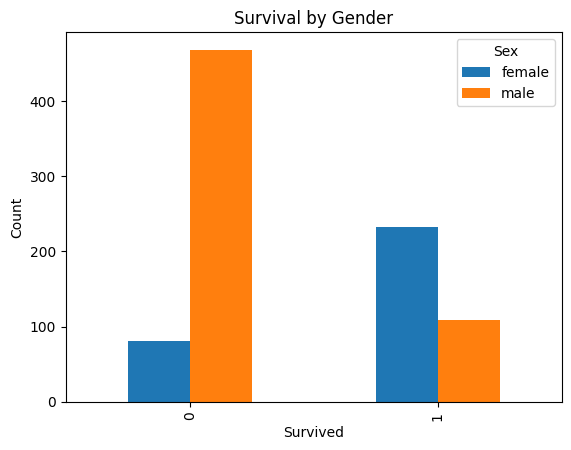

In [42]:
# Group the data by 'Survived' and 'Sex' and get the counts
survival_gender_counts = df.groupby(['Survived', 'Sex']).size().unstack()

# Plot the grouped data
survival_gender_counts.plot(kind='bar')

# Add title and labels
plt.title('Survival by Gender')
plt.xlabel('Survived')
plt.ylabel('Count')

# Show the plot
plt.show()

Let us pay attention to the code.


1.   `survival_gender_counts` holds the counts of number of survivors that are male and female. What is the type of this variable? How many rows and columns does this variable have? [2]

Dataframe object - 2D Array

It has 4 rows and 3 columns

2.   In the `survival_gender_counts.plot(kind='bar')` line, what does the `kind='bar'` parameter specify? How would the plot change if you used `kind='barh'` instead? [4]

It specifies the type of format you want to display the data as, in this case as a vertical bar graph

barh changes the graph into a horizontal bar graph

We can create the same plot with another library `Seaborn` that is built on top of `Matplotlib`.

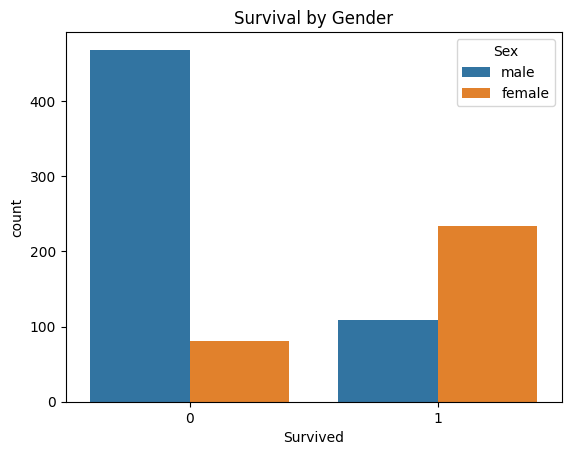

In [45]:
import seaborn as sns
sns.countplot(x='Survived', hue='Sex', data=df)

plt.title('Survival by Gender')
plt.show()

We used the function `countplot()` in `seaborn` to generate the bar plot showing the counts we need.

Explain what each of the parameters for `countplot()` specify. [6]

The x-axis label and what is being plotted on the graph, The title for the colors at the top of the graph and the values by which the the x parameter is being divided into (e.g. sex or class), and the dataset used for the column names and plotting the graph


By looking at the plot, do you think gender and survival were related? Explain why or why not.    [3]

Yes, a much larger proportion of the male passengers died than the female passengers and more females survived proportionally compared to the male passengers

In the Titanic dataset, `Pclass` refers to the passenger class, which indicates the socioeconomic status (SES) of the passengers. There are three classes:

* 1 = First class (Upper class)
* 2 = Second class (Middle class)
* 3 = Third class (Lower class)

Using `seaborn` library, create a count plot (similar to the one above) to show the relationship between survivors and passenger class.

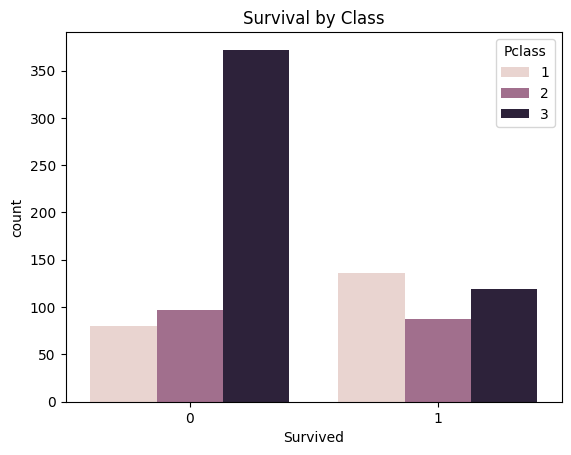

In [47]:
# Plot Survival by Passenger Class [6]

sns.countplot(x='Survived', hue='Pclass', data=df)

plt.title('Survival by Class')
plt.show()

By looking at the plot, do you think passenger class and survival were related? Explain why or why not. [3]

Yes, the least amount of people from 1st class died and the majority of people who did survive were from 1st class. The most amount of deaths were from the 3rd class, however, this could just be because of the majority of people on the titanic were 3rd class.